# 05. Exploratory Data Analysis

**Procurement Intelligence Platform** | Notebook 05 of 13

Before choosing models we study the series we want to forecast: trend, seasonality, stationarity, intermittency, leading indicators and the effect of the shocks.

| | |
|---|---|
| **Inputs** | `marts.fct_weekly_section`, `marts.fct_requisition_line`, `marts.fct_backlog_weekly` |
| **Outputs** | Modelling implications that drive notebooks 06 to 12 |
| **Skills shown** | Time-series EDA, statistical testing, data storytelling |

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from p2p.viz.theme import use_matplotlib, BRAND, SERIES, ORIGIN_COLORS, STATUS, shade_shocks
use_matplotlib()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
from p2p.data import weekly_section, query
ws = weekly_section()
company = ws.groupby("week_start")[["pr_lines", "cm_lines", "pm_lines", "restock_lines", "project_lines", "open_lines", "cash_out_usd",
                                    "cm_work_orders", "pm_planned_next_3w"]].sum()
print(f"{ws.section_id.nunique()} sections x {ws.week_start.nunique()} weeks "
      f"({ws.week_start.min().date()} to {ws.week_start.max().date()}); {len(ws):,} rows, no missing weeks: "
      f"{ws.groupby('section_id').week_start.count().nunique() == 1}")
display(company.describe().T[["mean", "std", "min", "50%", "max"]])

12 sections x 208 weeks (2022-01-03 to 2025-12-22); 2,496 rows, no missing weeks: True


,mean,std,min,50%,max
pr_lines,150.240,42.038,49.000,148.500,277.000
cm_lines,69.942,20.229,10.000,69.000,138.000
pm_lines,33.173,10.389,0.000,32.500,78.000
restock_lines,32.519,21.484,4.000,22.500,92.000
project_lines,14.606,22.418,0.000,0.000,94.000
open_lines,"1,797.269",216.977,"1,419.000","1,788.500","2,297.000"
cash_out_usd,"299,013.961","62,553.709","116,643.950","286,641.985","478,996.610"
cm_work_orders,50.038,14.391,9.000,50.000,91.000
pm_planned_next_3w,78.788,15.776,0.000,78.000,121.000


## 1. Trend and seasonality (STL decomposition)

STL splits the weekly company series into a smooth trend, a repeating yearly pattern and a remainder.

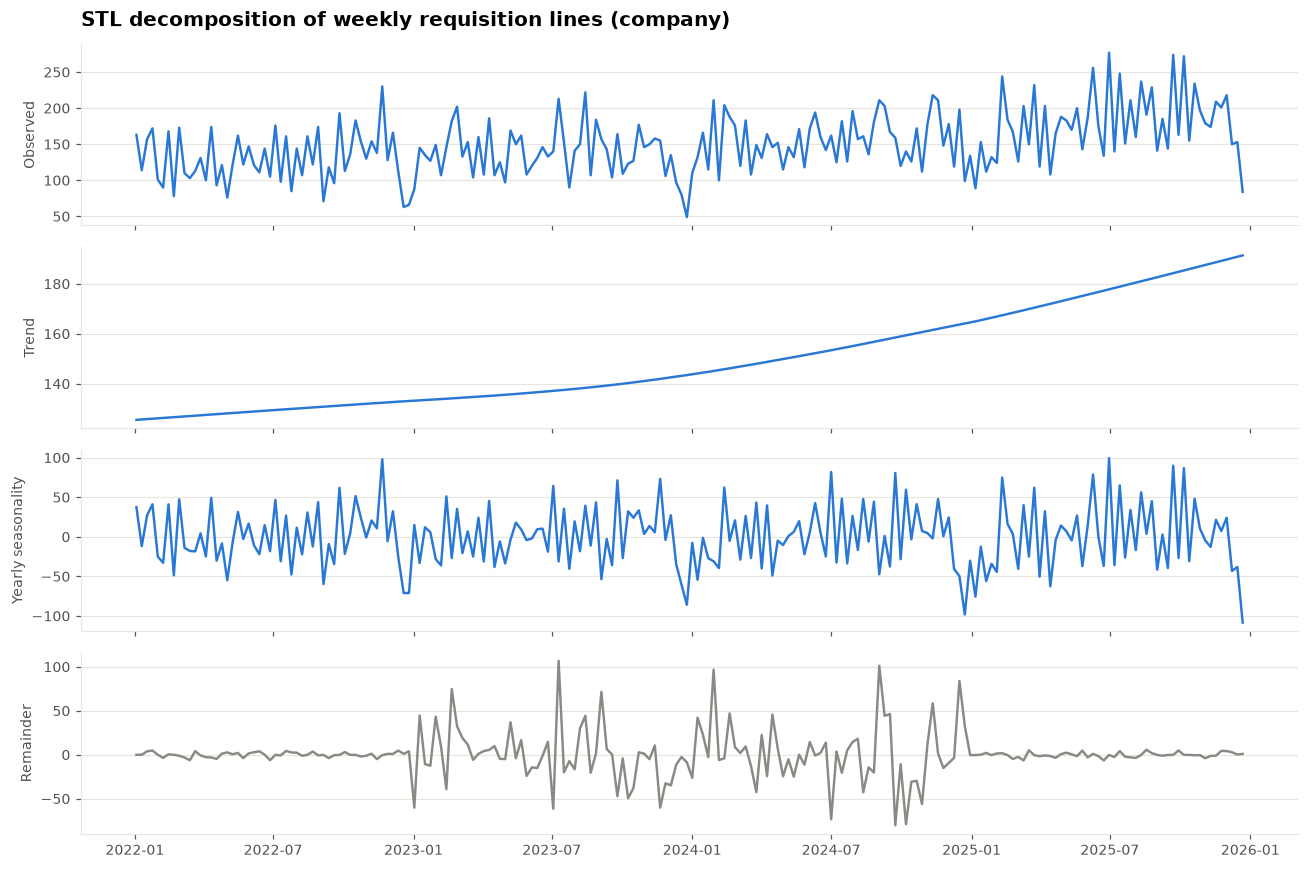

Trend strength 0.36 | seasonal strength 0.54 | trend growth 11.2% per year


In [3]:
from statsmodels.tsa.seasonal import STL
stl = STL(company.pr_lines, period=52, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, (lbl, s) in zip(axes, [("Observed", company.pr_lines), ("Trend", stl.trend), ("Yearly seasonality", stl.seasonal), ("Remainder", stl.resid)]):
    ax.plot(s.index, s.values, color=SERIES[0] if lbl != "Remainder" else BRAND["muted"], lw=1.6)
    ax.set_ylabel(lbl, fontsize=9)
axes[0].set_title("STL decomposition of weekly requisition lines (company)")
plt.tight_layout(); plt.show()

var = lambda x: np.var(x)
f_trend = max(0, 1 - var(stl.resid) / var(stl.trend + stl.resid))
f_season = max(0, 1 - var(stl.resid) / var(stl.seasonal + stl.resid))
growth = (stl.trend.iloc[-26:].mean() / stl.trend.iloc[:26].mean()) ** (1 / 3.5) - 1
print(f"Trend strength {f_trend:.2f} | seasonal strength {f_season:.2f} | trend growth {growth:.1%} per year")

**What we see.** A clear upward trend (about 11% a year, including the 2025 marine contract) and a yearly pattern (rainy-season
peak, December shutdown). Seasonal strength is 0.54 and trend strength 0.36 on a 0 to 1 scale. The remainder is large: one-off spikes
from projects.

**Modelling implication.** Models need a trend term, a yearly seasonal component (52 weeks) and robustness to spikes. Seasonal naive
alone will not be enough because the trend moves the level every year.

## 2. Seasonal profile by section

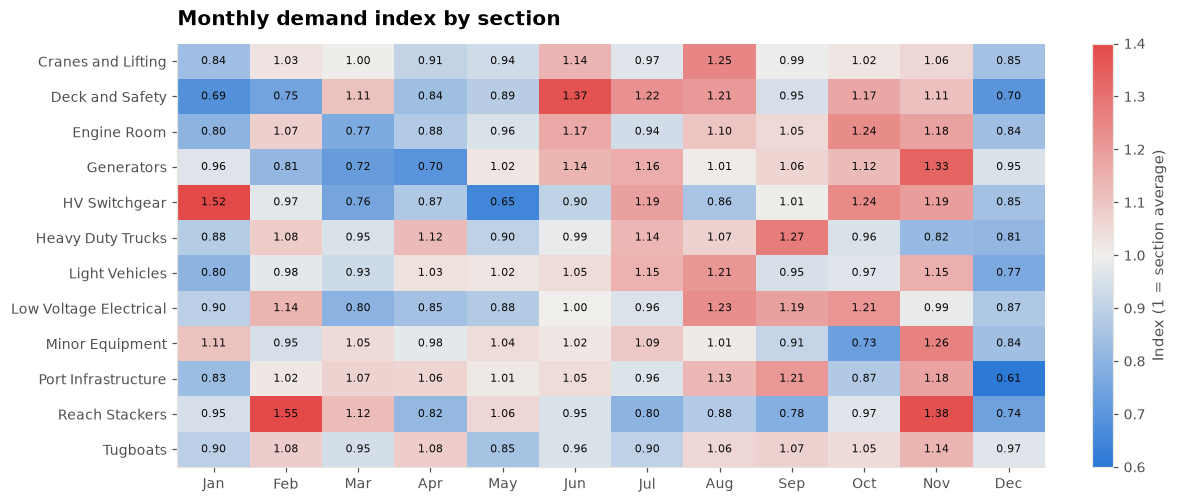

In [4]:
ws["month"] = ws.week_start.dt.month
prof = ws.groupby(["section_name", "month"]).pr_lines.mean().unstack()
prof = prof.div(prof.mean(axis=1), axis=0)
import matplotlib.colors as mcolors
div = mcolors.LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(prof.values, cmap=div, vmin=0.6, vmax=1.4, aspect="auto")
ax.set_yticks(range(len(prof))); ax.set_yticklabels(prof.index)
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
for i in range(prof.shape[0]):
    for j in range(12):
        ax.text(j, i, f"{prof.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color=BRAND["ink"])
ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.025, label="Index (1 = section average)")
ax.set_title("Monthly demand index by section")
plt.show()

**What we see.** December is low in almost every section (shutdown). Light Vehicles, Low Voltage Electrical and Port Infrastructure run
above average from August to October (rainy season), and November is high in most sections (restock budget push). The small sections
(HV Switchgear, Reach Stackers) show isolated hot spots such as February or January: these are project bursts, not seasonality.

**Modelling implication.** Seasonality differs by section, so a global model must know the section. Small sections are a trap: with
four years of data, a flexible seasonal model can mistake a one-off project for a yearly pattern and repeat it every year.

## 3. Stationarity and autocorrelation

,series,ADF p-value,KPSS p-value,verdict
0,Company lines,0.615,0.010,non-stationary
1,"Company lines, differenced",0.000,0.100,stationary
2,Open backlog,0.712,0.010,non-stationary
3,"Open backlog, differenced",0.000,0.100,stationary


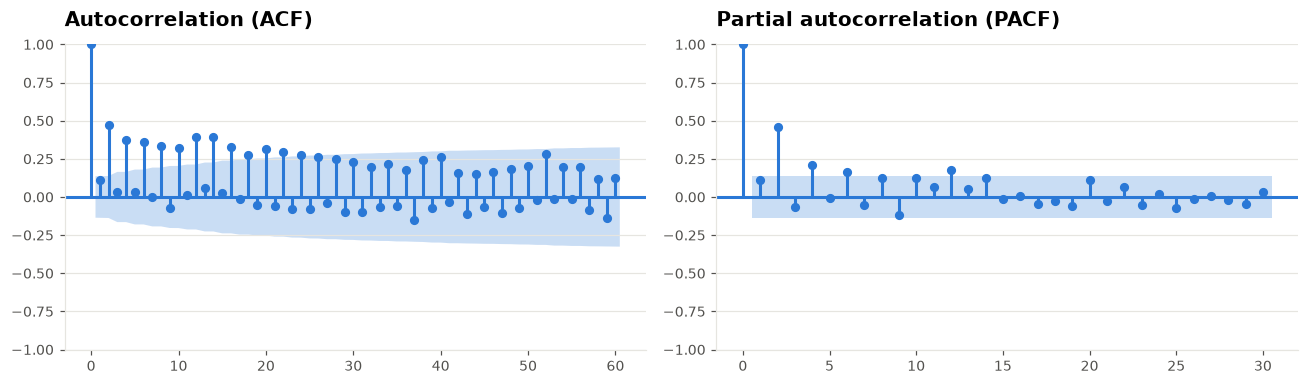

In [5]:
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.simplefilter("ignore", InterpolationWarning)   # KPSS p-values are capped at 0.01 and 0.10

def tests(y):
    adf_p = adfuller(y, autolag="AIC")[1]
    kpss_p = kpss(y, regression="c", nlags="auto")[1]
    return adf_p, kpss_p

rows = []
for name, y in [("Company lines", company.pr_lines), ("Company lines, differenced", company.pr_lines.diff().dropna()),
                ("Open backlog", company.open_lines), ("Open backlog, differenced", company.open_lines.diff().dropna())]:
    a, k = tests(y.values)
    rows.append({"series": name, "ADF p-value": a, "KPSS p-value": k,
                 "verdict": "stationary" if a < 0.05 and k > 0.05 else ("non-stationary" if a > 0.05 and k < 0.05 else "trend-stationary / mixed")})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(company.pr_lines, lags=60, ax=axes[0], color=SERIES[0], vlines_kwargs={"colors": SERIES[0]})
plot_pacf(company.pr_lines, lags=30, ax=axes[1], color=SERIES[0], vlines_kwargs={"colors": SERIES[0]}, method="ywm")
axes[0].set_title("Autocorrelation (ACF)"); axes[1].set_title("Partial autocorrelation (PACF)")
plt.tight_layout(); plt.show()

**What we see.** Both series are non-stationary in levels (ADF cannot reject a unit root, KPSS rejects stationarity) and stationary
after one difference. For requisition lines the cause is the moving level (trend and seasonality); the open backlog is a true stock that
accumulates new lines minus closures. The ACF decays slowly with a bump near lag 52 (yearly season) and alternates between odd and even
lags. The PACF spike at lag 2 is the fingerprint of the bi-weekly MRP restock.

**Modelling implication.** Requisition lines need models with a level that adapts (ETS, Theta, ARIMA) plus yearly and MRP-week
features. The backlog behaves like an integrated series, so naive and Theta will be hard benchmarks to beat for it.

## 4. Intermittency: at which level can we forecast?

The Syntetos-Boylan classification uses the average interval between demands (ADI) and the squared coefficient of variation of non-zero
demand (CV squared): smooth, erratic, intermittent or lumpy.

In [6]:
def sb_class(y):
    y = np.asarray(y)
    nz = y[y > 0]
    if len(nz) < 2:
        return np.nan, np.nan, "Too sparse"
    adi = len(y) / len(nz)
    cv2 = (nz.std() / nz.mean()) ** 2
    cls = ("Smooth" if cv2 < 0.49 else "Erratic") if adi < 1.32 else ("Intermittent" if cv2 < 0.49 else "Lumpy")
    return adi, cv2, cls

sec = pd.DataFrame([dict(zip(["ADI", "CV2", "class"], sb_class(g.pr_lines))) | {"section": s} for s, g in ws.groupby("section_name")])
mat = query("""
    select material_id, pr_week_start as week, count(*) as lines
    from marts.fct_requisition_line where pr_week_start between '2022-01-03' and '2025-12-22'
    group by all
""")
weeks = pd.date_range("2022-01-03", "2025-12-22", freq="W-MON")
mat_classes = mat.groupby("material_id").lines.apply(lambda s: sb_class(np.r_[s.values, np.zeros(len(weeks) - len(s))])[2])
print("Sections:"); display(sec.set_index("section").round(2))
print("Materials (1,500 spare parts):"); display(mat_classes.value_counts(normalize=True).rename("share").to_frame())

Sections:


,ADI,CV2,class
section,,,
Cranes and Lifting,1.000,0.250,Smooth
Deck and Safety,1.010,0.790,Erratic
Engine Room,1.020,0.690,Erratic
Generators,1.000,0.520,Erratic
HV Switchgear,1.060,1.380,Erratic
Heavy Duty Trucks,1.000,0.240,Smooth
Light Vehicles,1.000,0.160,Smooth
Low Voltage Electrical,1.000,0.290,Smooth
Minor Equipment,1.000,0.350,Smooth


Materials (1,500 spare parts):


,share
lines,
Intermittent,0.943
Too sparse,0.050
Smooth,0.004
Lumpy,0.003


**What we see.** Every section has demand almost every week (ADI close to 1). Seven sections are **smooth**, five are **erratic**
because project bursts make the size of demand volatile. At material level the picture flips: 94% of the 1,500 spare parts are
**intermittent** (ordered a few times a year) and 5% are too sparse to classify.

**Modelling implication.** Forecasting at material level would be dominated by zeros; that is the job of inventory policies (Croston,
TSB, safety stock), not of planning. We forecast at **section level** (the level at which workload and budget are planned) and keep
Croston and TSB in the arena as the intermittent-demand specialists.

## 5. Distribution of weekly counts

In [7]:
disp = ws.groupby("section_name").pr_lines.agg(["mean", "var"])
disp["variance_to_mean"] = disp["var"] / disp["mean"]
display(disp.round(2).sort_values("variance_to_mean", ascending=False))

,mean,var,variance_to_mean
section_name,,,
Port Infrastructure,8.580,70.950,8.270
HV Switchgear,5.160,40.530,7.850
Reach Stackers,14.270,109.670,7.680
Generators,14.060,104.170,7.410
Engine Room,9.690,68.600,7.080
Deck and Safety,8.430,58.360,6.920
Tugboats,11.480,62.870,5.480
Low Voltage Electrical,15.150,67.190,4.430
Cranes and Lifting,17.470,75.790,4.340


**What we see.** The variance is 3 to 8 times the mean in every section. For a Poisson process it would be 1: the data is
**over-dispersed**, mainly because of project bursts and correlated breakdowns. The erratic sections are the most over-dispersed.

**Modelling implication.** Gaussian intervals around a mean will be too narrow for the busiest weeks. We use count-aware losses
(Poisson objective for the gradient-boosting models, negative-binomial output for the neural networks) and evaluate intervals
explicitly (coverage, CRPS).

## 6. Leading indicators

A planner knows some things in advance. Do they actually lead demand?

In [8]:
def ccf(x, y, max_lag=6):
    return pd.Series({k: np.corrcoef(x[:-k] if k else x, y[k:])[0, 1] for k in range(0, max_lag + 1)})

cc = pd.DataFrame({
    "Planned PM work orders (next 3 weeks) -> PM lines": ccf(company.pm_planned_next_3w.values, company.pm_lines.values),
    "Corrective work orders -> CM lines": ccf(company.cm_work_orders.values, company.cm_lines.values),
})
cc.index.name = "lag (weeks)"
display(cc.round(2))
print("Correlation of requisition lines with fleet utilisation (same week):",
      round(np.corrcoef(ws.fleet_utilisation, ws.pr_lines)[0, 1], 2))

,Planned PM work orders (next 3 weeks) -> PM lines,Corrective work orders -> CM lines
lag (weeks),,
0,0.650,0.950
1,0.280,0.620
2,0.180,0.480
3,0.170,0.420
4,0.150,0.420
5,-0.030,0.400
6,0.070,0.390


Correlation of requisition lines with fleet utilisation (same week): 0.08


**What we see.**

* The planned-maintenance schedule correlates strongly with planned-maintenance requisitions **in the same week it is published**, and
  the schedule itself is known weeks ahead, so it is a legitimate **known-future covariate**.
* Corrective work orders turn into requisitions within the same week, so they explain demand but cannot be known in advance; they
  enter the models only as lagged features.
* Fleet utilisation has almost no direct link at section level (0.08). Its effect works through breakdowns, which the corrective work
  orders already capture.

**Modelling implication.** SARIMAX, Prophet, N-HiTS and the ML models receive the PM plan as a future covariate. This is a real
information advantage over univariate models, and the arena will measure whether it pays.

## 7. How the shocks show up in the process

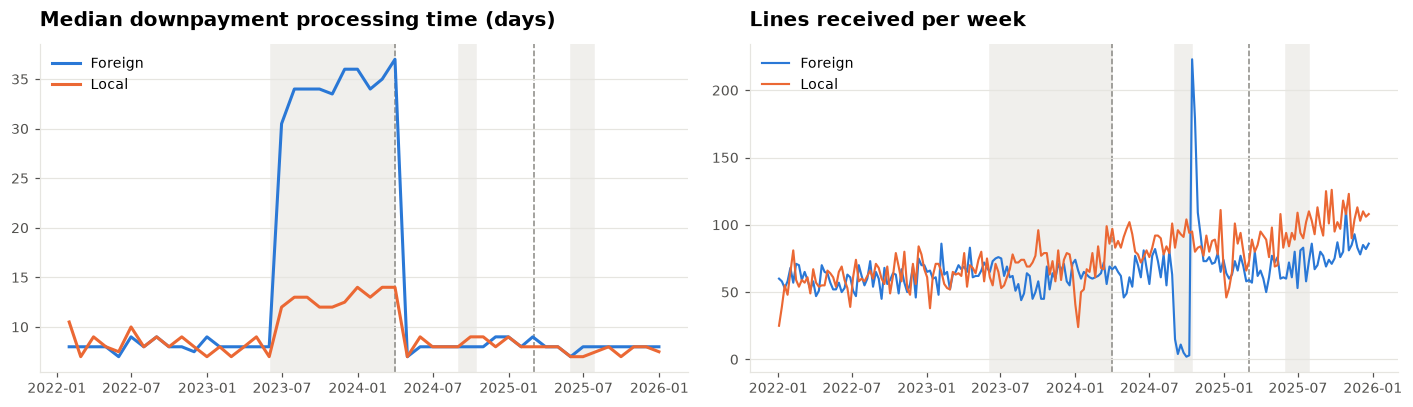

In [9]:
lines = query("""
    select po_approved_on, supplier_origin, downpayment_days, po_to_delivery_days, approval_days, approval_level, delivered_on
    from marts.fct_requisition_line where po_approved_on >= '2022-01-01' and supplier_origin in ('Local', 'Foreign')
""")
lines["po_approved_on"] = pd.to_datetime(lines.po_approved_on)
m = lines.set_index("po_approved_on").groupby("supplier_origin").resample("ME").downpayment_days.median().unstack(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for o in ["Foreign", "Local"]:
    axes[0].plot(m.index, m[o], label=o, color=ORIGIN_COLORS[o])
shade_shocks(axes[0], label=False); axes[0].legend(); axes[0].set_title("Median downpayment processing time (days)")
rec = query("select week_start, supplier_origin, sum(received_lines) as received from marts.fct_backlog_weekly where supplier_origin in ('Local','Foreign') group by all order by 1")
for o in ["Foreign", "Local"]:
    r = rec[rec.supplier_origin == o]
    axes[1].plot(r.week_start, r.received, label=o, color=ORIGIN_COLORS[o], lw=1.4)
shade_shocks(axes[1], label=False); axes[1].legend(); axes[1].set_title("Lines received per week")
plt.tight_layout(); plt.show()

**What we see.** During the FX crisis the median foreign downpayment jumped from about 8 days to more than a month, while local
downpayments barely moved. During the port congestion (grey band in late 2024) foreign receipts collapsed for six weeks and then
spiked when the port cleared, while local receipts continued.

**Modelling implication.** Shocks hit the **process** (durations), not only the demand. A model of the process (the Monte Carlo in
notebook 10) can represent them directly as "stage X takes longer", which a black-box time-series model cannot.

## 8. The backlog by stage

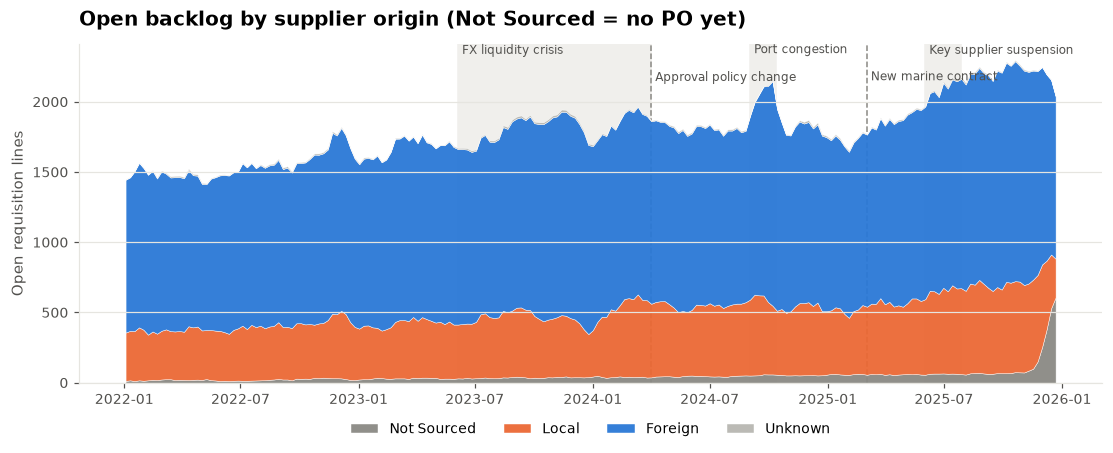

In [10]:
bl = query("""
    select week_start, supplier_origin, sum(open_lines) as open_lines
    from marts.fct_backlog_weekly group by all order by 1
""").pivot(index="week_start", columns="supplier_origin", values="open_lines").fillna(0)
order = ["Not Sourced", "Local", "Foreign", "Unknown"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.stackplot(bl.index, *[bl[c] for c in order if c in bl], labels=[c for c in order if c in bl],
             colors=[ORIGIN_COLORS[c] for c in order if c in bl], alpha=0.95, edgecolor="white", linewidth=0.3)
shade_shocks(ax); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
ax.set_ylabel("Open requisition lines"); ax.set_title("Open backlog by supplier origin (Not Sourced = no PO yet)")
plt.show()

**What we see.** The backlog grows from about 1,600 to about 2,200 open lines over four years, faster than demand. Foreign lines are the
largest and most volatile block; they swell during the FX crisis and the congestion. The "Not Sourced" block (requisitions without a PO)
is small but contains the oldest lines, as notebook 04 showed.

## 9. Summary: what the EDA tells the modelling

| Finding | Evidence | Implication |
|---|---|---|
| Trend plus yearly seasonality with big spikes | STL, strength measures | Trend-aware models, yearly features, robust losses |
| Seasonality differs by section | Monthly index heatmap | Section-aware global models or per-section models |
| Bi-weekly restock rhythm | PACF lag 2 | MRP-week feature |
| Sections are smooth, materials are intermittent | Syntetos-Boylan | Forecast at section level; keep Croston and TSB as challengers |
| Over-dispersed counts | Variance-to-mean ratio 2 to 7 | Poisson or negative-binomial losses, evaluate intervals |
| PM plan is a known-future driver | Cross-correlation | Exogenous covariate for SARIMAX, Prophet, N-HiTS and ML |
| Shocks change process durations | Downpayment and receipt charts | Process Monte Carlo for backlog, cash and what-if |
| Backlog is an integrated stock | KPSS and ADF | Naive and Theta are strong benchmarks for backlog |

**Next:** notebook 06 builds the features and the time-based split that keeps 2025 completely unseen.